# Módulo 2 — Entregable: interpolación a un punto y cierre

Ejercicio 4 (interpolación) + checkpoint de cierre del módulo (ver
[`README.md`](../README.md)).

### 📘 Ejemplo resuelto: el recorte sintético del Ejercicio 3

Este notebook usa el archivo `recorte_costa_central.nc` que guardó el Paso 4
de [`03_practica_recorte_dominio.ipynb`](03_practica_recorte_dominio.ipynb).
Si no existe, ejecuta antes ese notebook completo.

> **📍 Nota para curso con 2 grupos:** este notebook abre el recorte que guardó cada grupo en `03_practica_recorte_dominio.ipynb`, así que el dominio ya es el de tu grupo. Cambia solo el punto de interpolación (`punto_lat, punto_lon`) por uno dentro de tu recorte que no coincida con la grilla:
> - **Grupo 1 (Norte):** cerca de Piura, p. ej. `-5.5, -80.3`.
> - **Grupo 2 (Sur):** cerca de Arequipa, p. ej. `-16.1, -71.4`.

In [1]:
from pathlib import Path

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

ARCHIVO = "recorte_costa_central.nc"   # lo guarda el Paso 4 de 03_practica_recorte_dominio.ipynb
if not Path(ARCHIVO).exists():
    raise FileNotFoundError(f"No existe {ARCHIVO}: ejecuta primero 03_practica_recorte_dominio.ipynb completo.")

ds = xr.open_dataset(ARCHIVO)
ds

<xarray.Dataset> Size: 34kB
Dimensions:    (time: 192, latitude: 7, longitude: 3)
Coordinates:
  * time       (time) datetime64[ns] 2kB 2026-01-12 ... 2026-01-19T23:00:00
  * latitude   (latitude) float64 56B -8.0 -9.0 -10.0 -11.0 -12.0 -13.0 -14.0
  * longitude  (longitude) float64 24B -78.0 -77.0 -76.0
Data variables:
    t2m        (time, latitude, longitude) float32 16kB ...
    msl        (time, latitude, longitude) float32 16kB ...
Attributes:
    Conventions:  CF-1.7
    institution:  Datos sinteticos (curso Python-WRF) - NO son ERA5 real
    history:      Generado localmente sin conexion a Copernicus CDS

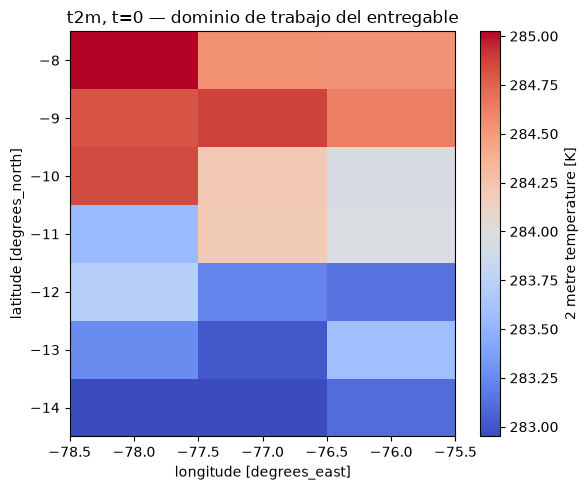

In [2]:
fig, ax = plt.subplots(figsize=(6, 5))
ds["t2m"].isel(time=0).plot(ax=ax, cmap="coolwarm")
ax.set_title("t2m, t=0 — dominio de trabajo del entregable")
fig.tight_layout()
plt.show()

## Elegir un punto que NO coincide con la grilla

In [3]:
punto_lat, punto_lon = -10.7, -77.1

lat_vals = ds.latitude.values
lon_vals = ds.longitude.values
en_grilla_lat = np.any(np.isclose(lat_vals, punto_lat))
en_grilla_lon = np.any(np.isclose(lon_vals, punto_lon))
print(f"¿El punto coincide con un nodo de grilla? lat: {en_grilla_lat}, lon: {en_grilla_lon}")

¿El punto coincide con un nodo de grilla? lat: False, lon: False


## Comparar `.sel(nearest)` vs. `.interp(linear)`

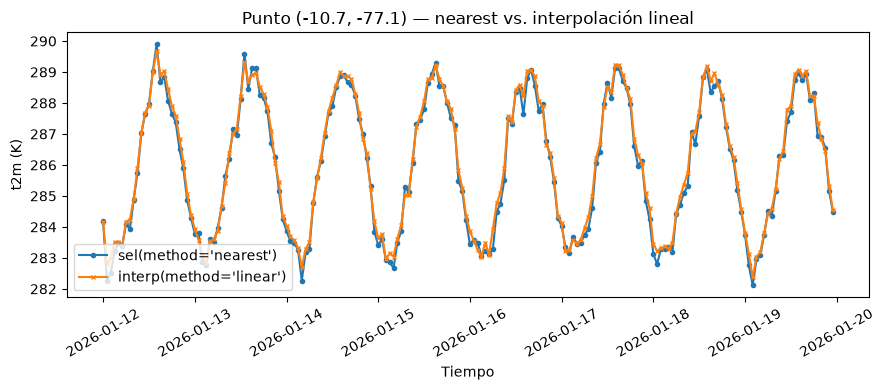

Diferencia absoluta media entre ambos métodos: 0.1743 K


In [4]:
serie_nearest = ds["t2m"].sel(latitude=punto_lat, longitude=punto_lon, method="nearest")
serie_interp = ds["t2m"].interp(latitude=punto_lat, longitude=punto_lon, method="linear")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ds.time, serie_nearest.values, label="sel(method='nearest')", marker="o", markersize=3)
ax.plot(ds.time, serie_interp.values, label="interp(method='linear')", marker="x", markersize=3)
ax.set_xlabel("Tiempo")
ax.set_ylabel("t2m (K)")
ax.set_title(f"Punto ({punto_lat}, {punto_lon}) — nearest vs. interpolación lineal")
ax.legend()
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()

diferencia_media = float(np.abs(serie_nearest - serie_interp).mean())
print(f"Diferencia absoluta media entre ambos métodos: {diferencia_media:.4f} K")

## Opcional — Verificación manual de la interpolación bilineal (un instante)

> Opcional: confirma con la fórmula que `.interp()` mezcla los cuatro
> vecinos según su distancia. Lo importante es la idea, no la fórmula.

In [5]:
t2m_t0 = ds["t2m"].isel(time=0)

i_lat_sup = np.where(lat_vals >= punto_lat)[0][-1]
i_lat_inf = i_lat_sup + 1
j_lon_izq = np.where(lon_vals <= punto_lon)[0][-1]
j_lon_der = j_lon_izq + 1

y1, y2 = lat_vals[i_lat_inf], lat_vals[i_lat_sup]
x1, x2 = lon_vals[j_lon_izq], lon_vals[j_lon_der]

Q11 = t2m_t0.values[i_lat_inf, j_lon_izq]
Q21 = t2m_t0.values[i_lat_inf, j_lon_der]
Q12 = t2m_t0.values[i_lat_sup, j_lon_izq]
Q22 = t2m_t0.values[i_lat_sup, j_lon_der]

x, y = punto_lon, punto_lat
manual = (
    Q11 * (x2 - x) * (y2 - y) +
    Q21 * (x - x1) * (y2 - y) +
    Q12 * (x2 - x) * (y - y1) +
    Q22 * (x - x1) * (y - y1)
) / ((x2 - x1) * (y2 - y1))

valor_interp = float(serie_interp.isel(time=0))
print(f"Cálculo manual (ley bilineal): {manual:.4f} K")
print(f"Resultado de .interp():       {valor_interp:.4f} K")
print(f"¿Coinciden dentro de tolerancia? -> {np.isclose(manual, valor_interp, atol=1e-3)}")

Cálculo manual (ley bilineal): 284.1715 K
Resultado de .interp():       284.1715 K
¿Coinciden dentro de tolerancia? -> True


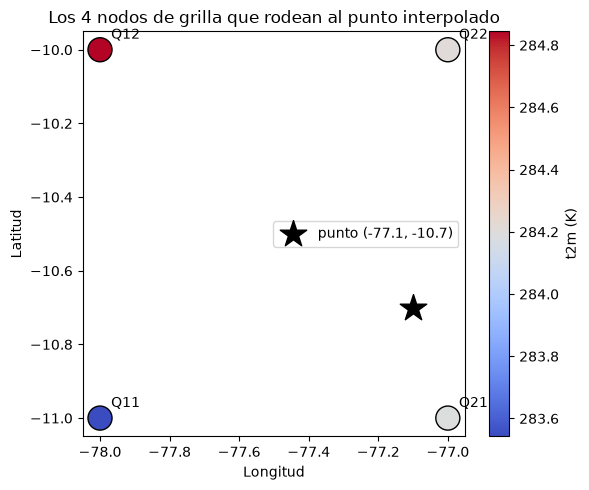

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))
nodos_x, nodos_y = [x1, x2, x1, x2], [y1, y1, y2, y2]
sc = ax.scatter(nodos_x, nodos_y, c=[Q11, Q21, Q12, Q22], s=300, cmap="coolwarm", edgecolor="k", zorder=2)
for xi, yi, label in zip(nodos_x, nodos_y, ["Q11", "Q21", "Q12", "Q22"]):
    ax.annotate(label, (xi, yi), textcoords="offset points", xytext=(8, 8))
ax.scatter([x], [y], marker="*", s=400, color="black", zorder=3, label=f"punto ({x:.1f}, {y:.1f})")
ax.set_xlabel("Longitud"); ax.set_ylabel("Latitud")
ax.set_title("Los 4 nodos de grilla que rodean al punto interpolado")
plt.colorbar(sc, ax=ax, label="t2m (K)")
ax.legend()
fig.tight_layout()
plt.show()

### ✍️ Tu turno — Ejercicio 4, con el ERA5 real

¿Qué temperatura daba ERA5 en la estación **Campo de Marte** (Lima,
−12.071, −77.043) el 13 de diciembre de 2024?

1. `t2m_c`: el `t2m` del ERA5 real convertido a **°C**;
2. `serie_nearest_real` y `serie_interp_real`: la serie en ese punto con
   `.sel(method="nearest")` y con `.interp(method="linear")`;
3. `diferencia_real`: la diferencia absoluta media entre las dos series
   (un `float`, redondeado a 2 decimales).

Después, compara: ¿la diferencia es mayor o menor que la del ejemplo
sintético? La grilla de ERA5 es de 0.25° (unos 28 km) y Lima está entre el
mar y los cerros.

In [7]:
# ✍️ TU TURNO
era5 = xr.open_dataset("../../../data/era_muestra/era5_peru_20241213.nc")
lat_cm, lon_cm = -12.071, -77.043     # Campo de Marte (SENAMHI)

t2m_c = None                          # ✍️ 1. de K a °C
serie_nearest_real = None             # ✍️ 2.
serie_interp_real = None              # ✍️ 2.
diferencia_real = None                # ✍️ 3.

In [8]:
# ✔️ COMPROBAR
if diferencia_real is None:
    print("⏳ Todavía no completas la celda anterior.")
elif float(serie_interp_real.max()) > 100:
    print("❌ Los valores siguen en kelvin: resta 273.15.")
elif round(float(serie_nearest_real.mean()), 2) != 19.79:
    print("❌ La serie nearest no coincide: ¿usaste lat_cm, lon_cm y method=\"nearest\"?")
elif round(float(serie_interp_real.mean()), 2) != 19.09:
    print("❌ La serie interpolada no coincide: ¿usaste .interp(latitude=..., longitude=...)?")
elif round(float(diferencia_real), 2) != 0.70:
    print("❌ Las series están bien; revisa la diferencia: abs(a - b).mean().")
else:
    print(f"✅ ¡Correcto! Diferencia media nearest vs. interp en Campo de Marte: {float(diferencia_real):.2f} °C")
    print(f"   (en el ejemplo sintético fue {diferencia_media:.2f} K)")

⏳ Todavía no completas la celda anterior.


## Checkpoint de cierre del módulo

**Pregunta:** ¿por qué `.sel(method="nearest")` y `.interp(method="linear")`
dan resultados distintos, y en qué situación usaría cada uno?

✍️ **Tu respuesta** (haz doble clic en esta celda y escribe debajo, con tus
palabras; usa lo que viste en Campo de Marte):

…

<details>
<summary>Ver una respuesta modelo (ábrela solo después de escribir la tuya)</summary>

`.sel(method="nearest")` devuelve el valor **exacto** del punto de grilla
más cercano, sin ningún cálculo adicional: es fiel al dato original, pero
«salta» entre nodos y nunca da un valor intermedio.

`.interp(method="linear")` **calcula** un valor nuevo, ponderado por la
distancia a los 4 nodos que rodean al punto (interpolación bilineal): es más
suave y más representativo de un punto exacto, pero ese valor no sale
directamente de ninguna simulación.

Se prefiere *nearest* para variables muy heterogéneas en el espacio (p. ej.
precipitación convectiva, donde un valor intermedio puede engañar) o cuando
los nodos vecinos representan superficies distintas (mar y tierra, como en
Lima). *Interp* sirve para variables suaves y continuas (temperatura,
presión) en terreno homogéneo.
</details>

---
**Fin del Módulo 2.** Siguiente:
[Módulo 3 — Descarga de datos de entrada](../../modulo_03_descarga_datos_entrada/README.md).